In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load All Data
data_fname = '../spreadsheet_20261012.csv'
header = ["temp","eps12","L1","N1","L2","N2","M2",
          "block_size", "start_frame",
          "K2","log_K2", "SEM_K2", "SEM_log_K2",
          "phi_all_dense","phi_all_dilute","phi1_dense","phi1_dilute","phi2_dense","phi2_dilute",
          "SEM_phi_all_dense", "SEM_phi_all_dilute", "SEM_phi1_dense", "SEM_phi1_dilute", "SEM_phi2_dense", "SEM_phi2_dilute",
          "rho_all_dense","rho_all_dilute","rho1_dense","rho1_dilute","rho2_dense","rho2_dilute",
          "SEM_rho_all_dense", "SEM_rho_all_dilute", "SEM_rho1_dense", "SEM_rho1_dilute", "SEM_rho2_dense", "SEM_rho2_dilute"]
data = np.genfromtxt(data_fname, delimiter=",", names=True)
temp, eps12 = data['temp'], data['eps12']
L1, N1, L2, N2, M2 = data['L1'], data['N1'], data['L2'], data['N2'], data['M2']
mean_dense_rho, mean_dilute_rho = data['rho2_dense'], data['rho2_dilute']
K2, logK2 = data['K2'], data['log_K2']

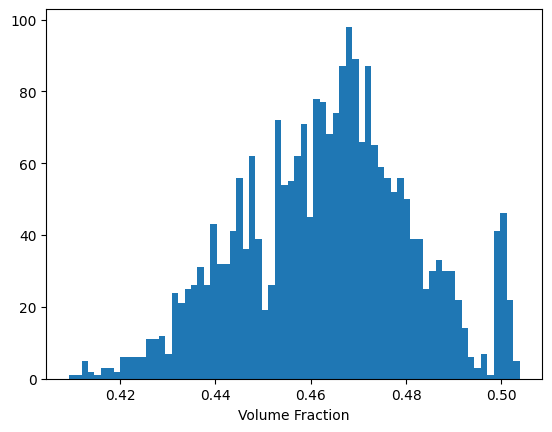

Min Volume Fraction: 0.40918652461607763
Max Volume Fraction: 0.503825271837352


In [6]:
## Volume fraction range
rho_dense_all = data['rho_all_dense']
phi_dense_all = data['phi_all_dense']
plt.hist(phi_dense_all, bins=70)
plt.xlabel('Volume Fraction')
plt.savefig('../2-Plots/1_1_vol_frac_hist.png')
plt.show()
lo_phi, hi_phi = np.min(phi_dense_all), np.max(phi_dense_all)
print(f"Min Volume Fraction: {lo_phi}\nMax Volume Fraction: {hi_phi}")

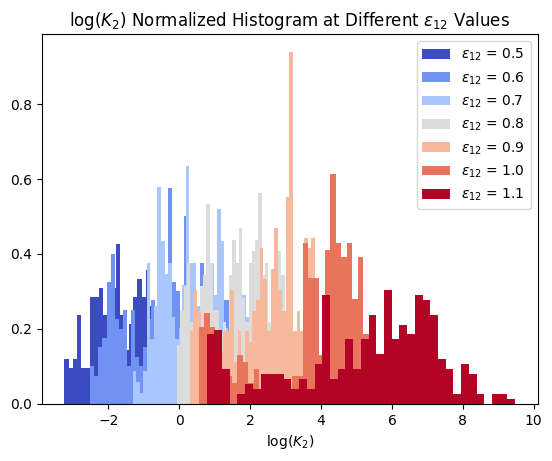

In [65]:
## Spread of log(K2) vs eps12
eps12_values = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1]
edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(eps12_values)))
for eps, edge in zip(eps12_values, edgecols):
    mask = np.where(eps12 == eps)
    logK2_sample = logK2[mask]
    plt.hist(logK2_sample, bins=40, density=True, color=edge, label=rf"$\epsilon_{{12}}$ = {eps}")

plt.xlabel(r'$\log(K_2)$')
plt.title(r'$\log(K_2)$ Normalized Histogram at Different $\epsilon_{12}$ Values')
plt.legend()
plt.savefig('../2-Plots/1_2a_logK2_eps12_hist.png')
plt.show()

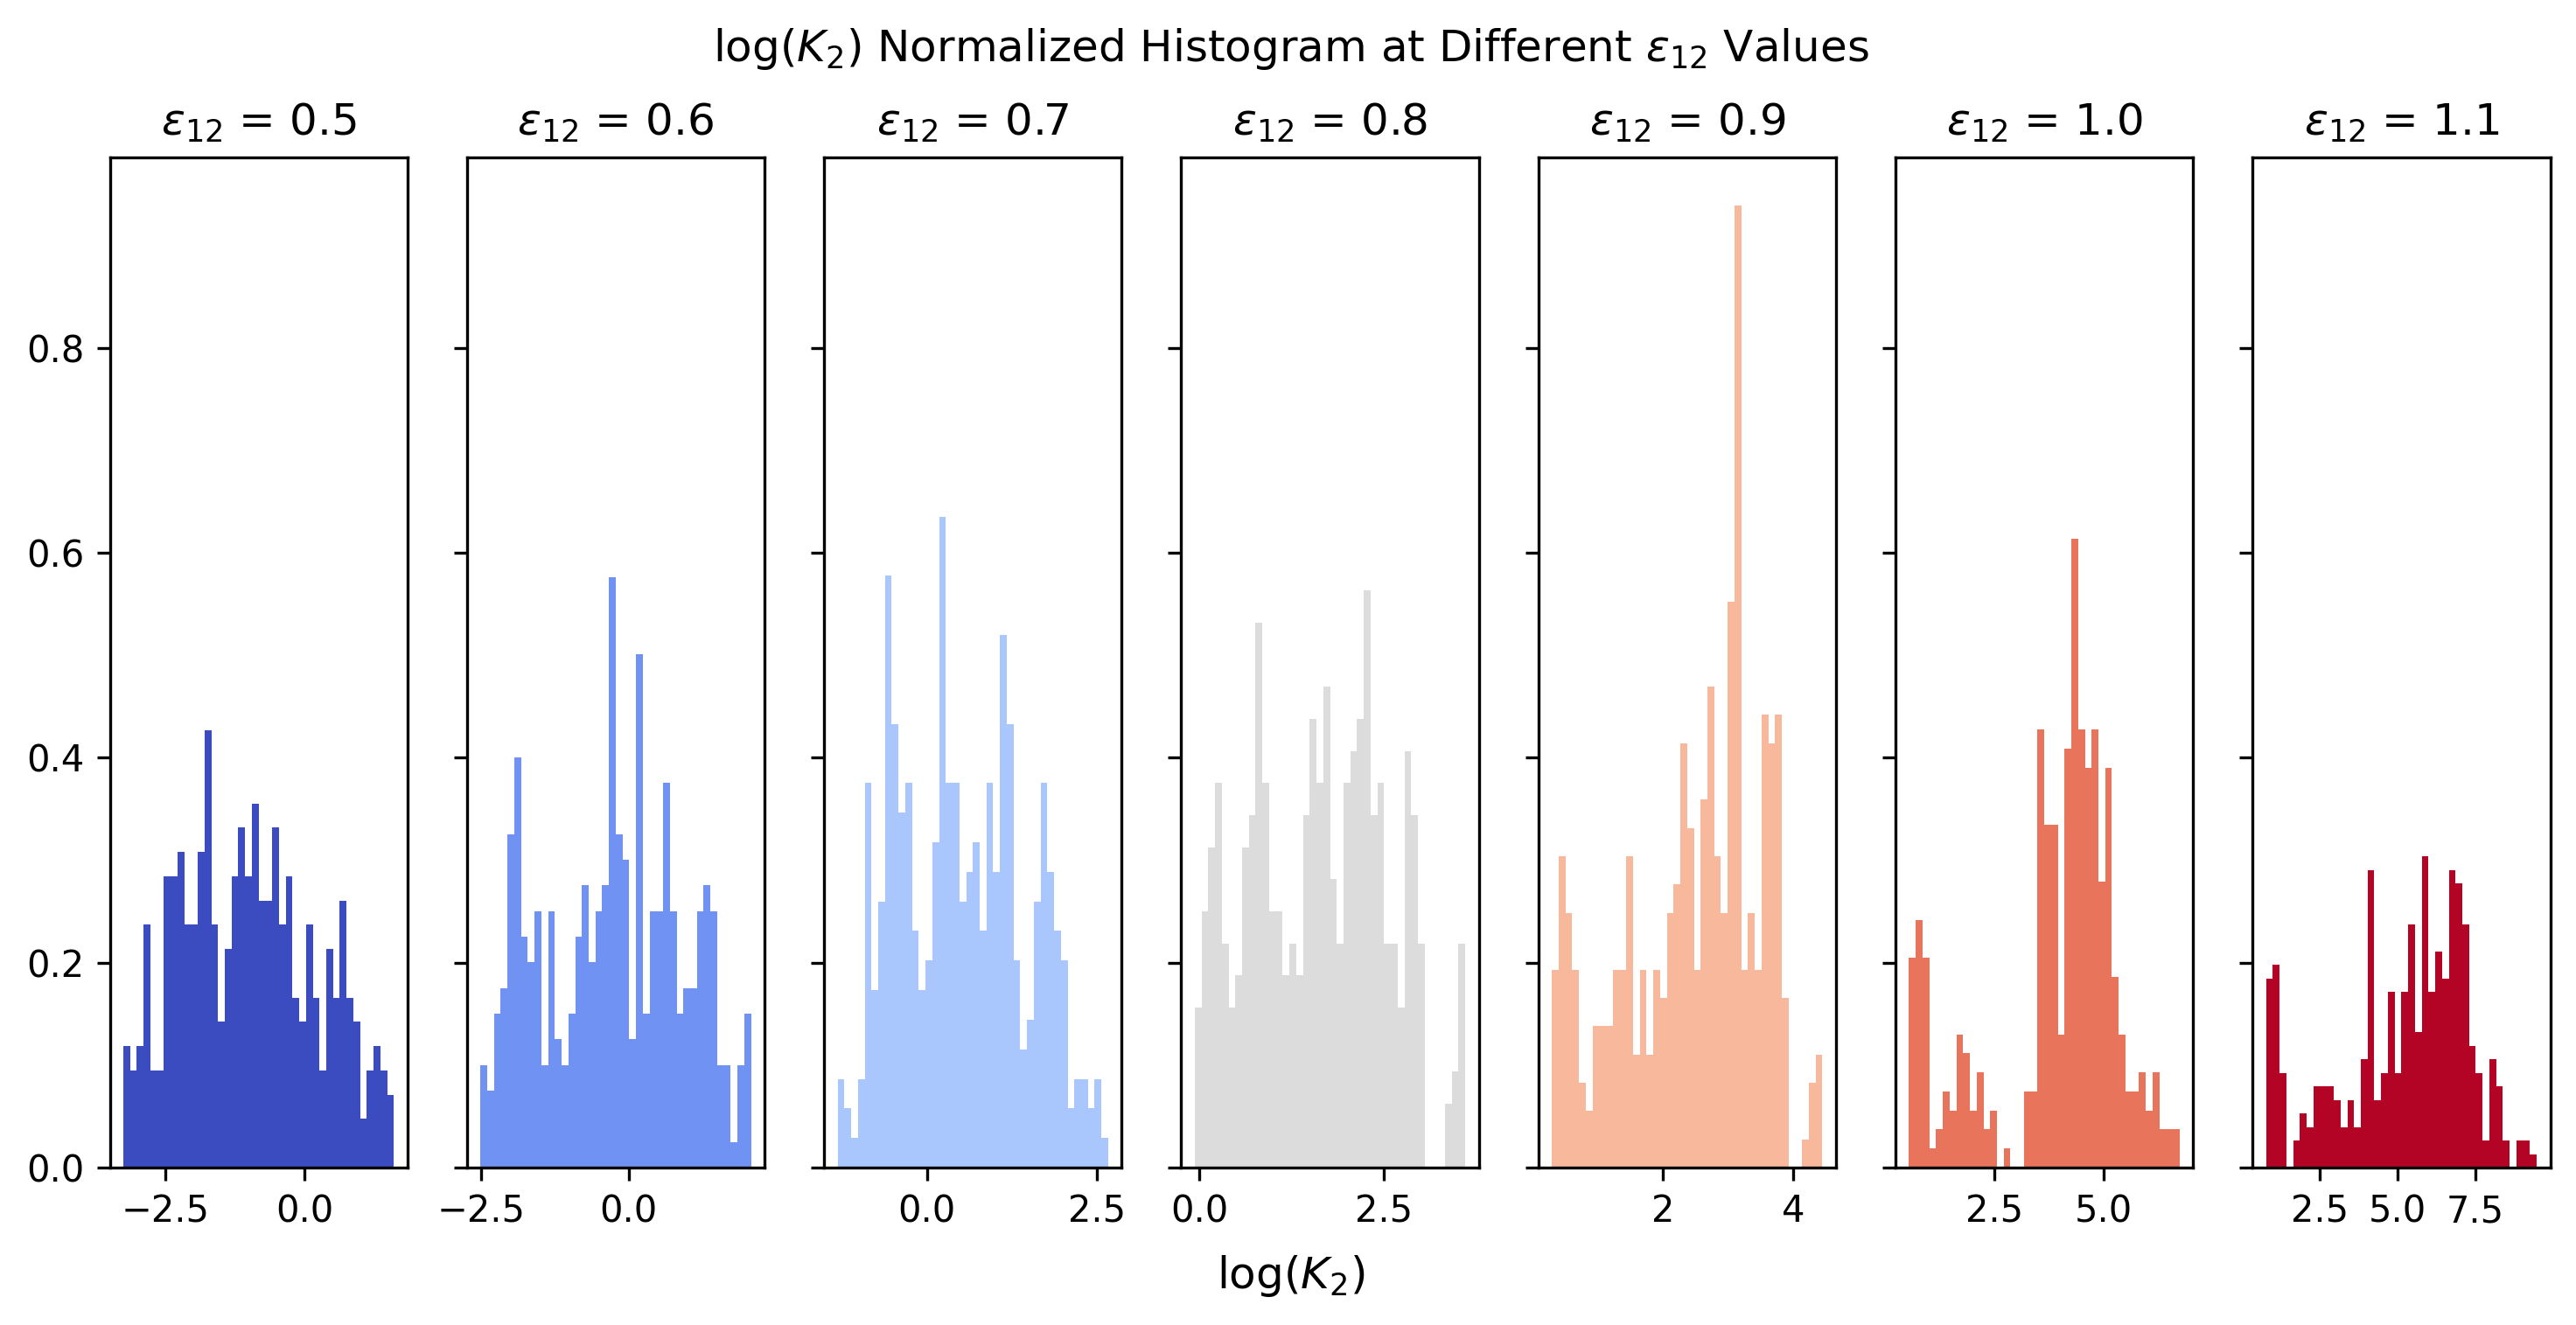

In [64]:
## Spread of log(K2) vs eps12
logK2 = data['log_K2']
eps12_values = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1]
edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(eps12_values)))
fig, ax = plt.subplots(1, 7, figsize=(12, 5), dpi=300, sharey=True)
for i, (eps, edge) in enumerate(zip(eps12_values, edgecols)):
    mask = np.where(eps12 == eps)
    logK2_sample = logK2[mask]
    ax[i].hist(logK2_sample, bins=40, density=True, color=edge)
    ax[i].set_title(rf"$\epsilon_{{12}}$ = {eps}")
fig.supxlabel(r'$\log(K_2)$')
fig.suptitle(r'$\log(K_2)$ Normalized Histogram at Different $\epsilon_{12}$ Values')
plt.savefig('../2-Plots/1_2b_logK2_eps12_hist_subplot.png')
plt.show()

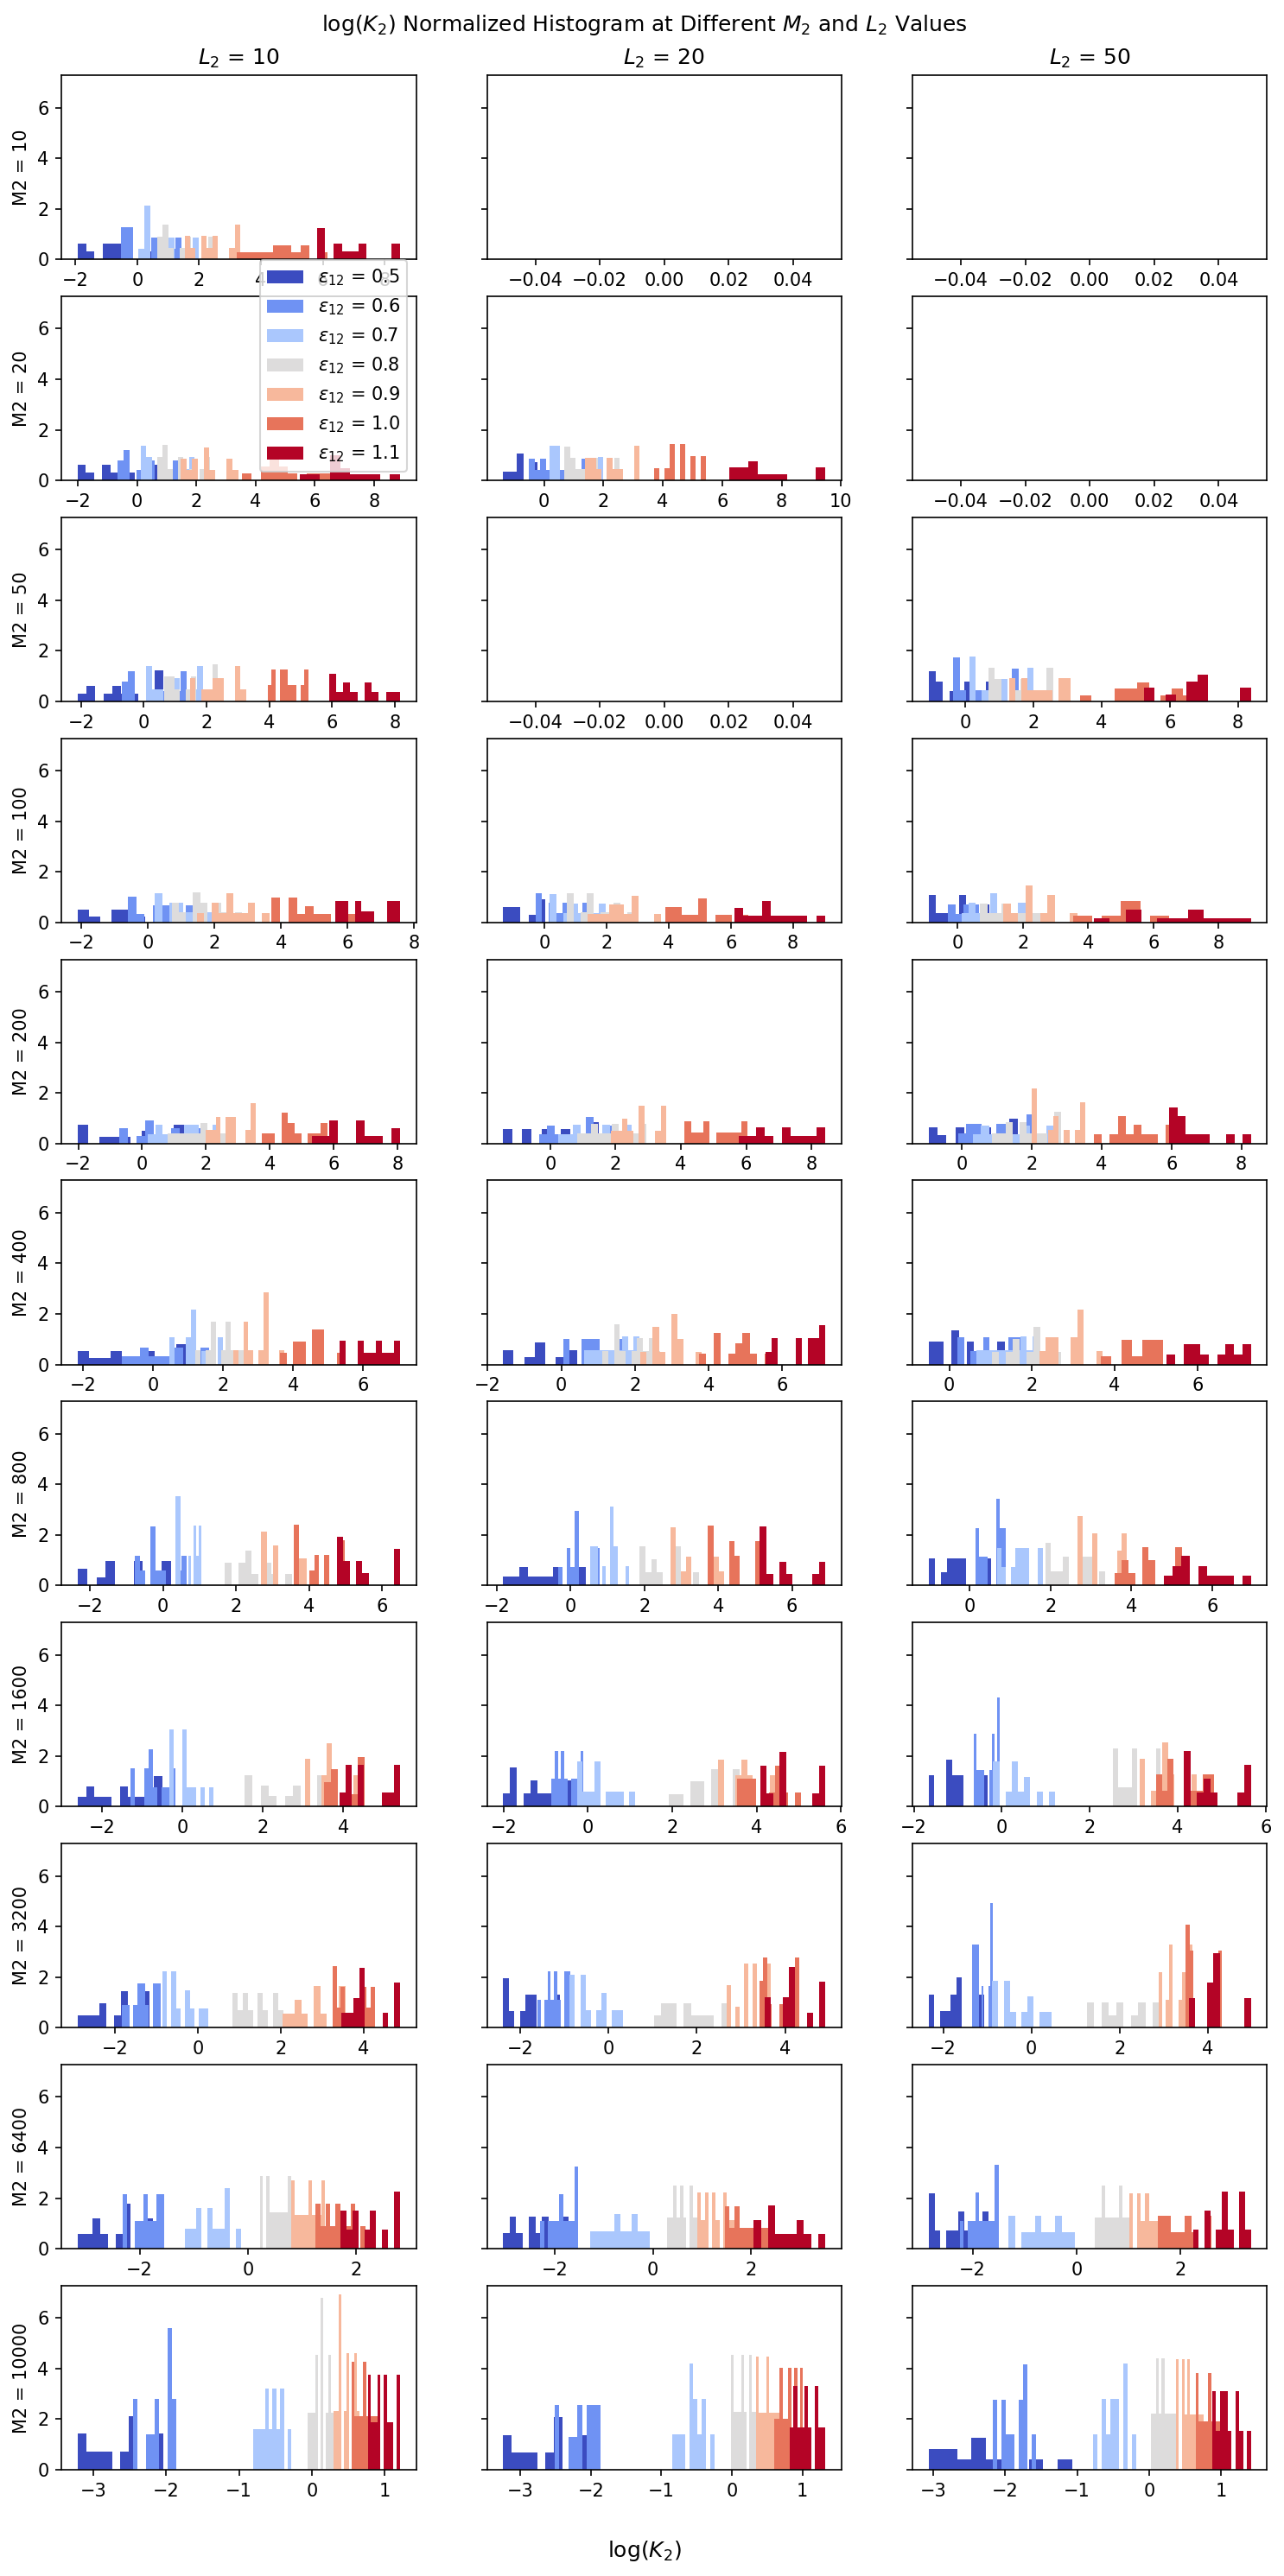

In [57]:
## Spread of log(K2) vs eps12 with M2 as rows and L2 as columns
L2, M2 = data['L2'], data['M2']
M2_values = np.array(np.unique(M2), dtype=int)
L2_values = [10, 20, 50]

fig, ax = plt.subplots(11, 3, figsize=(12, 24), dpi=150, sharey=True)
for i, m2 in enumerate(M2_values):
    ax[i, 0].set_ylabel(f'M2 = {m2}')
    for j, l2 in enumerate(L2_values):
        if i == 0:
            ax[i, j].set_title(rf'$L_2$ = {l2}')
        edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(eps12_values)))
        for eps, edge in zip(eps12_values, edgecols):
            mask = np.where( (M2 == m2) & (L2 == l2) & (eps12 == eps) )
            logK2_sample = logK2[mask]
            if (i == 1) and (j == 0):
                ax[i, j].hist(logK2_sample, bins=10, density=True, color=edge, label=rf"$\epsilon_{{12}}$ = {eps}")
            else:
                ax[i, j].hist(logK2_sample, bins=10, density=True, color=edge)
ax[1, 0].legend()
fig.supxlabel(r"$\log(K_2)$", y=0.08)
fig.suptitle(r'$\log(K_2)$ Normalized Histogram at Different $M_2$ and $L_2$ Values', y=0.90)
plt.savefig('../2-Plots/1_2c_logK2_hist_rowM2_colL2.png')
plt.show()
